### FAILED: The references galaxies are not used on the SOM, only to match calibration to the bins. 

In [14]:
import pickle
import numpy as np

DATA = "data"

with open(f"{DATA}/som_200_5colours_rand.pkl", "rb") as f:
    som = pickle.load(f)

print("Loaded SOM object type:", type(som))
print("n_vectors:", getattr(som, "n_vectors", None))
print("n_dim:", getattr(som, "n_dim", None))
print("codebook shape:", getattr(som, "codebook", None).shape if getattr(som, "codebook", None) is not None else None)
print("umatrix shape:", getattr(som, "umatrix", None).shape if getattr(som, "umatrix", None) is not None else None)


Loaded SOM object type: <class 'somoclu.train.Somoclu'>
n_vectors: 10395422
n_dim: 5
codebook shape: (200, 200, 5)
umatrix shape: (200, 200)


In [21]:
import pickle
import numpy as np

DATA = "data"
with open(f"{DATA}/som_200_5colours_rand.pkl", "rb") as f:
    som = pickle.load(f)

bmus = getattr(som, "bmus", None)
print("som.bmus type:", type(bmus))
if bmus is not None:
    bmus = np.asarray(bmus)
    print("som.bmus shape:", bmus.shape, "dtype:", bmus.dtype)


som.bmus type: <class 'numpy.ndarray'>
som.bmus shape: (10395422, 2) dtype: int32


In [15]:
DATA = "data"

accept = np.load(f"{DATA}/accept_fc.npy")
photometric_sample = np.load(f"{DATA}/photometric_sample_fc.npy")
reference_sample   = np.load(f"{DATA}/reference_sample_fc.npy")
reference_labels   = np.load(f"{DATA}/reference_labels_fc_fc.npy").astype(np.int32)

print("accept:", accept.shape, accept.dtype, "true:", accept.sum())
print("photometric_sample:", photometric_sample.shape, photometric_sample.dtype, photometric_sample.min(), photometric_sample.max())
print("reference_sample:", reference_sample.shape, reference_sample.dtype, reference_sample.min(), reference_sample.max())
print("reference_labels:", reference_labels.shape, reference_labels.dtype, reference_labels.min(), reference_labels.max())


accept: (80347373,) bool true: 80304361
photometric_sample: (72273925,) int64 0 80304360
reference_sample: (8030436,) int64 3 80304351
reference_labels: (8030436,) int32 0 10


In [16]:
import pandas as pd

DATA = "data"

# Load only a tiny sample to see columns fast
mag_head = pd.read_parquet(f"{DATA}/magnitudes.parquet").head(5)
print("magnitudes.parquet columns:\n", list(mag_head.columns))
mag_head


magnitudes.parquet columns:
 ['scatmag_g', 'scatmag_r', 'scatmag_u', 'scatmag_z', 'scatmag_y', 'scatmag_i']


,scatmag_g,scatmag_r,scatmag_u,scatmag_z,scatmag_y,scatmag_i
0,15.119246,14.360945,16.668835,13.699193,13.516685,13.977361
1,18.328945,17.719140,19.689352,17.281090,17.187695,17.421803
2,17.792992,17.443205,18.921532,17.199406,17.147938,17.265898
3,17.745901,17.349146,18.926174,17.042292,16.995653,17.130037
4,13.585487,13.205040,14.508188,12.933062,12.861006,13.008277


In [43]:
print("som.n_dim:", som.n_dim)
print("som.codebook shape:", np.asarray(som.codebook).shape)
print(som.codebook[5][2])


som.n_dim: 5
som.codebook shape: (200, 200, 5)
[0.19419731 0.85541797 0.8031771  0.14147377 0.10583629]


In [23]:
import pandas as pd

DATA="data"
mags = pd.read_parquet(f"{DATA}/magnitudes.parquet")
print(mags.shape)
print(mags.columns.tolist())
mags.head()


(80347373, 6)
['scatmag_g', 'scatmag_r', 'scatmag_u', 'scatmag_z', 'scatmag_y', 'scatmag_i']


,scatmag_g,scatmag_r,scatmag_u,scatmag_z,scatmag_y,scatmag_i
0,15.119246,14.360945,16.668835,13.699193,13.516685,13.977361
1,18.328945,17.719140,19.689352,17.281090,17.187695,17.421803
2,17.792992,17.443205,18.921532,17.199406,17.147938,17.265898
3,17.745901,17.349146,18.926174,17.042292,16.995653,17.130037
4,13.585487,13.205040,14.508188,12.933062,12.861006,13.008277


In [25]:
band_cols = ['scatmag_u', 'scatmag_g', 'scatmag_r', 'scatmag_i', 'scatmag_z', 'scatmag_y']

M = mags[band_cols].to_numpy(dtype=np.float32)

# 5 colours from 6 bands is typical; with 5 bands you only get 4 colours.
# If you truly need 5 features, they may have used:
# - 5 raw mags, or
# - 4 colours + 1 mag, or
# - 5 colours if there is an extra band.
#
# Example: 4 colours + i-band mag as the 5th feature:
u,g,r,i,z,y = [M[:,k] for k in range(M.shape[1])]
X_all = np.stack([u-g, g-r, r-i, i-z, z-y], axis=1).astype(np.float32)

print("X_all:", X_all.shape, X_all.dtype)


X_all: (80347373, 5) float32


In [26]:
accept = np.load(f"{DATA}/accept_fc.npy")
reference_sample = np.load(f"{DATA}/reference_sample_fc.npy")
photometric_sample = np.load(f"{DATA}/photometric_sample_fc.npy")

# If magnitudes.parquet includes the extra trailing row like full_catalogue:
# drop last row to match your earlier logic if needed.
# (You can detect mismatch by comparing lengths.)
print("len(mags):", len(mags), "len(accept):", len(accept))

# Apply accept mask to mags
mags_acc = mags.iloc[np.flatnonzero(accept)].reset_index(drop=True)
print("len(mags_acc):", len(mags_acc))

# Now X_acc must correspond to the same indexing as reference_sample / photometric_sample


len(mags): 80347373 len(accept): 80347373
len(mags_acc): 80304361


In [40]:
# Build X for accepted catalogue rows
M_acc = mags_acc[band_cols].to_numpy(dtype=np.float32)
u,g,r,i,z, y = [M_acc[:,k] for k in range(M_acc.shape[1])]
X_acc = np.stack([u-g, g-r, r-i, i-z, z-y], axis=1).astype(np.float32)

X_ref = X_acc[reference_sample]   # reference_sample are indices into accepted catalogue rows
print("X_ref:", X_ref.shape)



X_ref: (8030436, 5)
[0.77311134 1.2594662  0.34672737 0.1275711  0.03866005]


In [41]:
print(X_ref[0])

[0.77311134 1.2594662  0.34672737 0.1275711  0.03866005]


In [29]:
# Somoclu expects float32
X_ref = np.asarray(X_ref, dtype=np.float32)

bmus_ref = som.get_bmus(X_ref)  # returns (N_ref, 2) usually as (y,x)
bmus_ref = np.asarray(bmus_ref, dtype=np.int32)
print("bmus_ref:", bmus_ref.shape, bmus_ref.min(axis=0), bmus_ref.max(axis=0))


bmus_ref: (8030436, 2) [0 0] [4 0]


In [30]:
H=W=200
node_indices_ref = bmus_ref[:,0]*W + bmus_ref[:,1]
print("node_indices_ref:", node_indices_ref.shape, node_indices_ref.min(), node_indices_ref.max())


node_indices_ref: (8030436,) 0 800


In [31]:
ref_counts_per_node = np.bincount(node_indices_ref, minlength=H*W)
print("nodes with >=1 ref:", np.sum(ref_counts_per_node > 0))
print("max ref in a node:", ref_counts_per_node.max())


nodes with >=1 ref: 5
max ref in a node: 3641756


In [32]:
import numpy as np

H = W = 200
N = H * W

print("bmus_ref shape:", bmus_ref.shape, "dtype:", bmus_ref.dtype)
print("bmus_ref y-range:", int(bmus_ref[:,0].min()), int(bmus_ref[:,0].max()))
print("bmus_ref x-range:", int(bmus_ref[:,1].min()), int(bmus_ref[:,1].max()))

node_indices_ref = (bmus_ref[:,0] * W + bmus_ref[:,1]).astype(np.int32)
print("node_indices_ref range:", int(node_indices_ref.min()), int(node_indices_ref.max()))

# How many unique nodes?
uniq = np.unique(node_indices_ref)
print("unique nodes:", uniq.size, "  (should be >> 5)")
print("first 20 unique:", uniq[:20])

# Quick check for obvious transpose issue
node_indices_ref_xy = (bmus_ref[:,1] * W + bmus_ref[:,0]).astype(np.int32)
uniq_xy = np.unique(node_indices_ref_xy)
print("\n[swap y/x] node_indices_ref_xy range:", int(node_indices_ref_xy.min()), int(node_indices_ref_xy.max()))
print("[swap y/x] unique nodes:", uniq_xy.size)

# Assert plausibility
if node_indices_ref.max() < 10000 or np.unique(node_indices_ref).size < 1000:
    print("\nWARNING: Reference BMUs look collapsed / not spanning the 200x200 grid.")
    print("Most common causes:")
    print("  1) bmus_ref is not (y,x) in [0..199] each")
    print("  2) features scaling mismatch => everything maps to a tiny region")
    print("  3) som is not actually 200x200, or is using different grid dims")
    print("Check som.n_columns / som.n_rows if available, and confirm feature normalization.")


bmus_ref shape: (8030436, 2) dtype: int32
bmus_ref y-range: 0 4
bmus_ref x-range: 0 0
node_indices_ref range: 0 800
unique nodes: 5   (should be >> 5)
first 20 unique: [  0 200 400 600 800]

[swap y/x] node_indices_ref_xy range: 0 4
[swap y/x] unique nodes: 5

Most common causes:
  1) bmus_ref is not (y,x) in [0..199] each
  2) features scaling mismatch => everything maps to a tiny region
  3) som is not actually 200x200, or is using different grid dims
Check som.n_columns / som.n_rows if available, and confirm feature normalization.


nodes with >=1 ref: 5
max ref in a node: 3641756


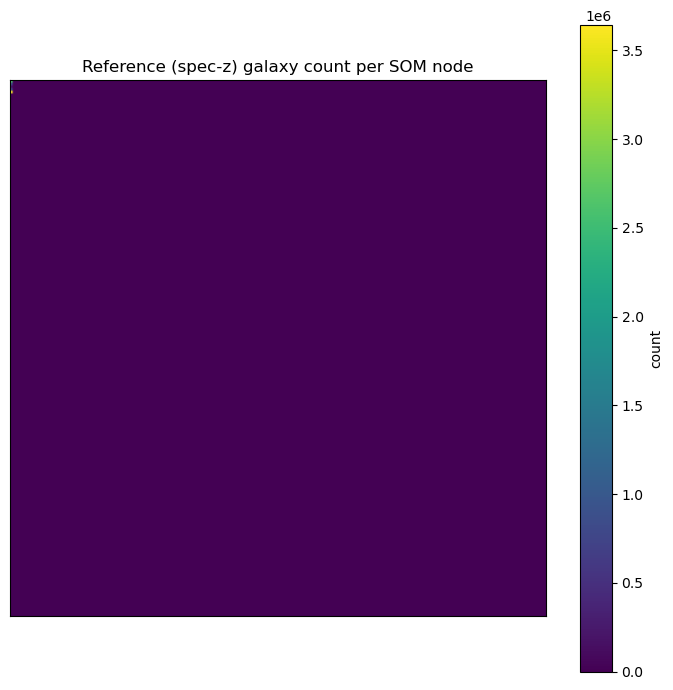

In [33]:
import matplotlib.pyplot as plt

H = W = 200
N = H * W

ref_counts = np.bincount(node_indices_ref, minlength=N).astype(np.int64)
ref_counts_grid = ref_counts.reshape(H, W)

print("nodes with >=1 ref:", int((ref_counts > 0).sum()))
print("max ref in a node:", int(ref_counts.max()))

plt.figure(figsize=(7,7))
plt.imshow(ref_counts_grid, origin="upper")
plt.title("Reference (spec-z) galaxy count per SOM node")
plt.xticks([]); plt.yticks([])
plt.colorbar(label="count")
plt.tight_layout()
plt.show()


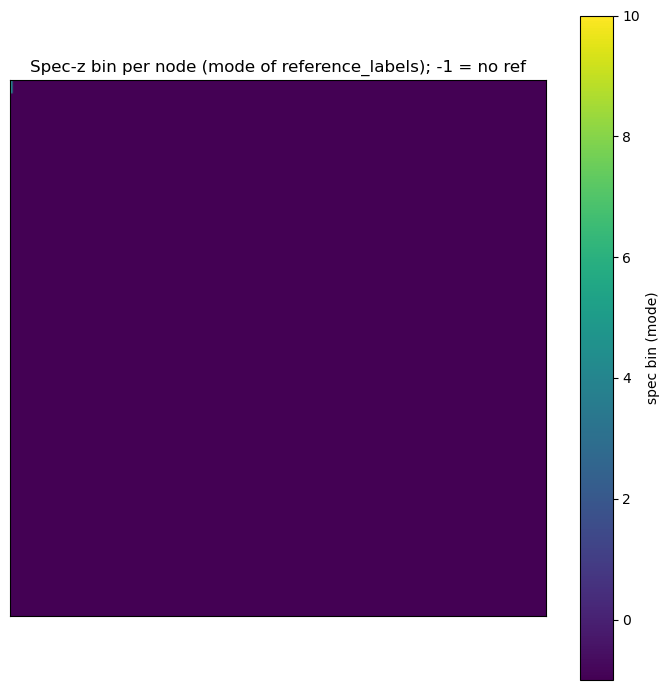

In [34]:
import numpy as np
import matplotlib.pyplot as plt

K = 11
H = W = 200
N = H * W

# node_indices_ref: (N_ref,)
# reference_labels: (N_ref,) in [0..10]
node_indices_ref = node_indices_ref.astype(np.int32)
reference_labels = reference_labels.astype(np.int32)

# sort by node for fast grouping
order = np.argsort(node_indices_ref)
nodes_sorted = node_indices_ref[order]
labels_sorted = reference_labels[order]

spec_bin_per_node = np.full(N, -1, dtype=np.int32)

# walk contiguous blocks of same node id
start = 0
while start < nodes_sorted.size:
    node = int(nodes_sorted[start])
    end = start + 1
    while end < nodes_sorted.size and nodes_sorted[end] == node:
        end += 1

    # labels for this node
    labs = labels_sorted[start:end]
    counts = np.bincount(labs, minlength=K)
    spec_bin_per_node[node] = int(np.argmax(counts))

    start = end

spec_bin_grid = spec_bin_per_node.reshape(H, W)

plt.figure(figsize=(7,7))
plt.imshow(spec_bin_grid, vmin=-1, vmax=K-1, origin="upper")
plt.title("Spec-z bin per node (mode of reference_labels); -1 = no ref")
plt.xticks([]); plt.yticks([])
plt.colorbar(label="spec bin (mode)")
plt.tight_layout()
plt.show()


In [36]:
import numpy as np
import matplotlib.pyplot as plt

K = 11
H = W = 200
N = H * W

# initial_node_bins should be (N,)
bins0 = np.asarray(initial_node_bins, dtype=np.int32).reshape(H, W)

ref_mask = (ref_counts_grid > 0)

plt.figure(figsize=(7,7))
plt.imshow(bins0, vmin=0, vmax=K-1, origin="upper")
plt.title("Initial node bins (photo-z style) with ref-node overlay")
plt.xticks([]); plt.yticks([])
plt.colorbar(label="node bin (0..10)")

# overlay ref nodes as dots (or contour)
ys, xs = np.where(ref_mask)
plt.scatter(xs, ys, s=3, c="white", alpha=0.8, linewidths=0)

plt.tight_layout()
plt.show()


NameError: name 'initial_node_bins' is not defined

In [ ]:
plt.figure(figsize=(7,7))
plt.imshow(bins0, vmin=0, vmax=K-1, origin="upper")
plt.title("Initial node bins with ref-node counts overlay")
plt.xticks([]); plt.yticks([])
plt.colorbar(label="node bin (0..10)")

ys, xs = np.where(ref_counts_grid > 0)
sizes = np.clip(ref_counts_grid[ys, xs] / np.max(ref_counts_grid), 0, 1) * 40 + 2
plt.scatter(xs, ys, s=sizes, c="white", alpha=0.7, linewidths=0)

plt.tight_layout()
plt.show()


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

mask = (ref_counts > 0)
agree = np.zeros(N, dtype=np.int8)
agree[mask] = (initial_node_bins[mask].astype(np.int32) == spec_bin_per_node[mask]).astype(np.int8)

agree_grid = agree.reshape(H, W)

plt.figure(figsize=(7,7))
plt.imshow(agree_grid, vmin=0, vmax=1, origin="upper")
plt.title("Agreement on ref nodes: initial_bin == spec_bin_mode (1=yes, 0=no)")
plt.xticks([]); plt.yticks([])
plt.colorbar(label="agreement")
plt.tight_layout()
plt.show()

print("Agreement rate on ref nodes:",
      float(agree[mask].mean()) if mask.any() else np.nan)
